<a href="https://colab.research.google.com/github/s-waqas-uzair/AtomCamp--AI-Bootcamp/blob/main/ML_Assignment_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🎓 ML Practice Assignment
## Regression & Classification

**Submitted by:** Syed Waqas Uzair

**Course:** Machine Learning — Atom Camp Bootcamp

**Date:** 4th October 2026 **(late submission)**

---

This notebook covers **two supervised machine learning tasks**:

| # | Task | Dataset | Models |
|---|------|---------|--------|
| 1 | 📈 Used Car Price Prediction | `Span_new.csv` | Linear Regression, Polynomial Regression |
| 2 | 🛍️ Customer Return Prediction | `Returns_data.csv` | Logistic Regression, Naïve Bayes |


---
## Step 0: Import Libraries

We import all required libraries here at the top so they are available throughout the notebook.

| Library | Purpose |
|---------|---------|
| `pandas` | Data loading and manipulation |
| `numpy` | Numerical operations |
| `matplotlib` / `seaborn` | Visualizations |
| `sklearn` | Machine learning models and evaluation |

In [ ]:
# ============================================================
#  LIBRARY IMPORTS — Run this cell first
# ============================================================

# Data handling
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, PolynomialFeatures
from sklearn.pipeline import Pipeline

# Regression Models
from sklearn.linear_model import LinearRegression

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

# Regression Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Classification Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report, roc_curve
)

# Display & style settings
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.3f}'.format)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 14})

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


---
## Step 0b: Upload Data Files

Since we are working in **Google Colab**, files are not stored permanently.
Run the cell below to upload your data files from your computer.

> **Upload both files when prompted:**
> - `Span_new.csv` — Car dataset for Part 1
> - `Returns_data.csv` — Customer returns dataset for Part 2

In [ ]:
# Upload CSV files from your local computer to Google Colab
from google.colab import files

print("📂 A file picker will appear below.")
print("   Please select and upload BOTH CSV files:\n")
print("   1. Span_new.csv")
print("   2. Returns_data.csv\n")

uploaded = files.upload()

print(f"\n✅ Uploaded files: {list(uploaded.keys())}")

📂 A file picker will appear below.
   Please select and upload BOTH CSV files:

   1. Span_new.csv
   2. Returns_data.csv



Saving Returns_data.csv to Returns_data (1).csv
Saving Span_new.csv to Span_new (1).csv

✅ Uploaded files: ['Returns_data (1).csv', 'Span_new (1).csv']


---
---
# 🚗 PART 1: Used Car Price Prediction
## Task: Regression

**Goal:** Build models to **predict the price** of a used car based on its characteristics.

**Dataset:** `Span_new.csv` — a dataset of used car listings

**Models to Apply:**
- **Linear Regression** — finds the best straight-line fit between features and price
- **Polynomial Regression** — extends linear regression to capture curved (non-linear) relationships

---

## Step 1: Load the Car Dataset

We load the CSV file into a **pandas DataFrame** — a table-like structure that makes data easy to work with.

In [ ]:
# Load the car dataset
# index_col=0 skips the unnamed row-number column at the front
df = pd.read_csv('Span_new.csv', index_col=0)

print(f"✅ Dataset loaded successfully!")
print(f"   Rows   : {df.shape[0]:,}")
print(f"   Columns: {df.shape[1]}")
print(f"\nColumn names: {list(df.columns)}")
print("\nFirst 5 rows:")
df.head()

✅ Dataset loaded successfully!
   Rows   : 92,385
   Columns: 10

Column names: ['ID', 'make', 'model', 'months_old', 'power', 'gear_type', 'fuel_type', 'kms', 'price', 'age']

First 5 rows:


,ID,make,model,months_old,power,gear_type,fuel_type,kms,price,age
0,97860,Porsche,911,240.000,210.000,manual,gasoline,202000.000,999999,1998.000
1,27821,Ford,Mustang,54.000,487.000,manual,gasoline,30000.000,685000,2013.000
2,97801,Porsche,911,358.000,220.000,manual,gasoline,56300.000,555555,1988.000
3,98251,Porsche,911,14.000,368.000,manual,gasoline,2800.000,470000,2016.000
4,98250,Porsche,911,3.000,515.000,unknown,gasoline,10.000,450000,2017.000


---
## Step 2: Exploratory Data Analysis (EDA)

Before building any model, we must **understand the data**:
- What columns do we have?
- Are there missing values?
- What do the distributions look like?
- Which features are correlated with price?


In [ ]:
# ── 2.1 Data Types and Non-Null Counts ──────────────────────
print("=" * 55)
print("  COLUMN INFORMATION")
print("=" * 55)
df.info()

  COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
Index: 92385 entries, 0 to 93990
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   ID          92385 non-null  int64  
 1   make        92385 non-null  object 
 2   model       92385 non-null  object 
 3   months_old  92385 non-null  float64
 4   power       92385 non-null  float64
 5   gear_type   92385 non-null  object 
 6   fuel_type   92385 non-null  object 
 7   kms         92385 non-null  float64
 8   price       92385 non-null  int64  
 9   age         92385 non-null  float64
dtypes: float64(4), int64(2), object(4)
memory usage: 7.8+ MB


In [ ]:
# ── 2.2 Check for Missing Values ────────────────────────────
print("=" * 45)
print("  MISSING VALUES PER COLUMN")
print("=" * 45)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({
    'Missing Count': missing,
    'Missing %':     missing_pct
})

# Show only columns that have at least 1 missing value
has_missing = missing_summary[missing_summary['Missing Count'] > 0]
if len(has_missing) == 0:
    print("  ✅ No missing values found!")
else:
    print(has_missing)

  MISSING VALUES PER COLUMN
  ✅ No missing values found!


In [ ]:
# ── 2.3 Summary Statistics for Numerical Columns ────────────
print("Summary Statistics:")
df.describe()

Summary Statistics:


,ID,months_old,power,kms,price,age
count,92385.000,92385.000,92385.000,92385.000,92385.000,92385.000
mean,55127.579,63.781,99.818,83161.963,16511.689,2012.238
std,33146.299,56.872,42.749,75231.339,15568.471,4.752
min,25.000,1.000,0.000,1.000,200.000,1987.000
25%,25434.000,17.000,77.000,18616.000,8500.000,2009.000
50%,53909.000,46.000,88.000,66687.000,13345.000,2014.000
75%,83611.000,97.000,110.000,129000.000,19990.000,2016.000
max,113143.000,372.000,809.000,497000.000,999999.000,2017.000


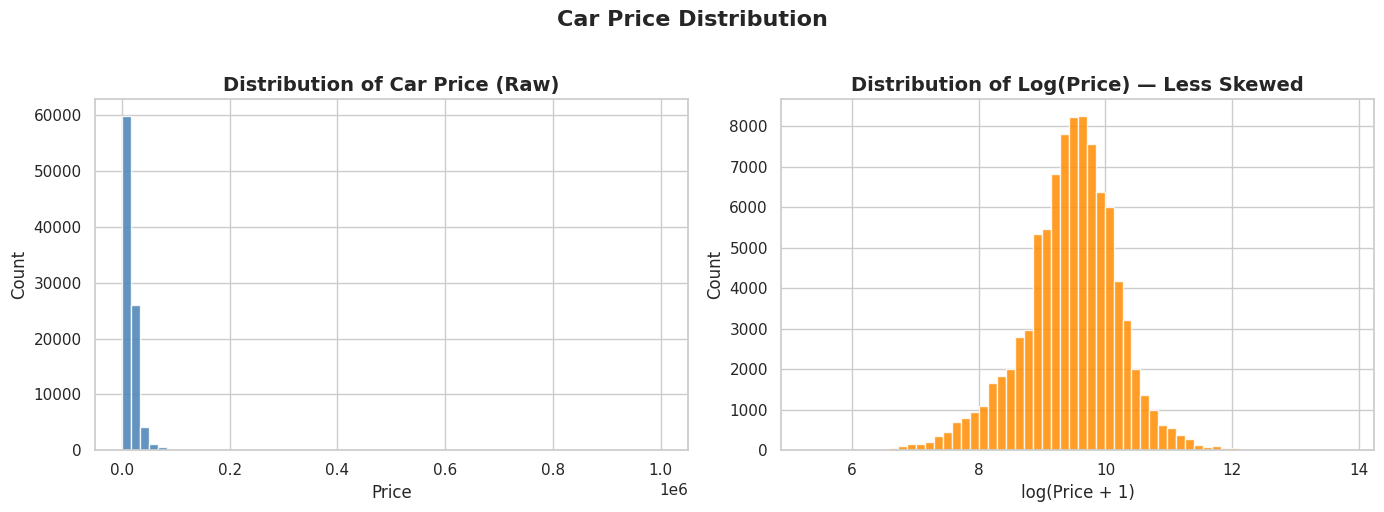

ℹ️  Car prices are right-skewed (long tail on the right).
   We will use log(price) as our target to improve model performance.


In [ ]:
# ── 2.4 Distribution of the Target Variable (Price) ─────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Raw price distribution
axes[0].hist(df['price'], bins=60, color='steelblue', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribution of Car Price (Raw)', fontweight='bold')
axes[0].set_xlabel('Price')
axes[0].set_ylabel('Count')

# Right: Log-transformed price (log makes skewed data more symmetric)
axes[1].hist(np.log1p(df['price']), bins=60, color='darkorange', edgecolor='white', alpha=0.85)
axes[1].set_title('Distribution of Log(Price) — Less Skewed', fontweight='bold')
axes[1].set_xlabel('log(Price + 1)')
axes[1].set_ylabel('Count')

plt.suptitle('Car Price Distribution', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Note about log transformation
print("ℹ️  Car prices are right-skewed (long tail on the right).")
print("   We will use log(price) as our target to improve model performance.")

In [ ]:
# ── 2.5 Unique Values in Categorical Columns ─────────────────
print("Unique values in categorical columns:\n")
for col in ['make', 'gear_type', 'fuel_type']:
    n_unique = df[col].nunique()
    top_vals = df[col].value_counts().head(5)
    print(f"  [{col}]  →  {n_unique} unique values")
    print(f"           Top 5: {dict(top_vals)}")
    print()

Unique values in categorical columns:

  [make]  →  36 unique values
           Top 5: {'Bmw': np.int64(10546), 'Audi': np.int64(9368), 'Volkswagen': np.int64(8749), 'Renault': np.int64(6379), 'Opel': np.int64(6136)}

  [gear_type]  →  4 unique values
           Top 5: {'manual': np.int64(66584), 'automatic': np.int64(24275), 'unknown': np.int64(1234), 'semi-automatic': np.int64(292)}

  [fuel_type]  →  6 unique values
           Top 5: {'diesel': np.int64(70699), 'gasoline': np.int64(21028), 'hybrid': np.int64(470), 'electric': np.int64(92), 'unknown': np.int64(53)}



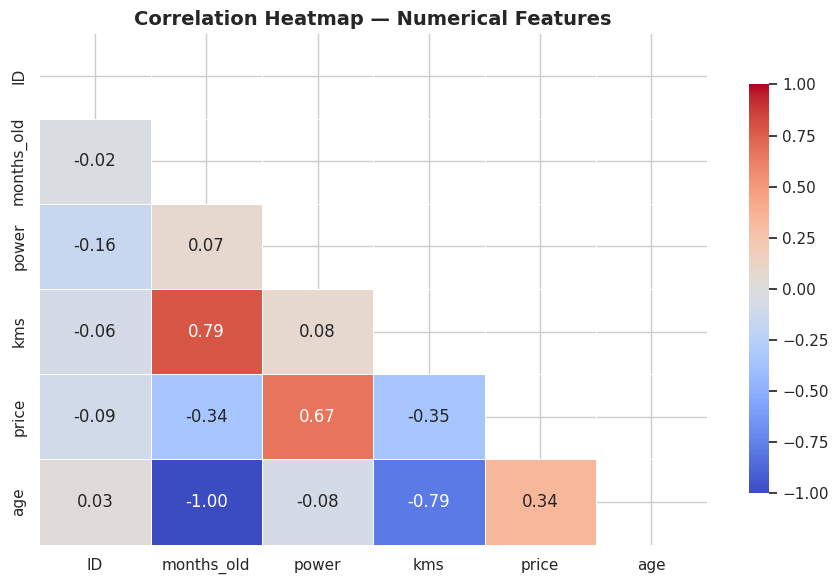

ℹ️  Values close to +1 or -1 indicate strong correlation.
   Values close to 0 indicate little to no correlation.


In [ ]:
# ── 2.6 Correlation Heatmap ──────────────────────────────────
# Shows how strongly numerical features relate to each other and to price
num_cols = df.select_dtypes(include='number').columns.tolist()

plt.figure(figsize=(9, 6))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide upper triangle (redundant)

sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='coolwarm',
    mask=mask, linewidths=0.5, vmin=-1, vmax=1,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap — Numerical Features', fontweight='bold')
plt.tight_layout()
plt.show()

print("ℹ️  Values close to +1 or -1 indicate strong correlation.")
print("   Values close to 0 indicate little to no correlation.")

### 📊 Correlation Heatmap — Interpretation

**How to read this:** Values range from **-1** (perfect negative correlation) to **+1** (perfect positive correlation). Zero means no linear relationship.

---

#### 🔴 Strongest Correlations with `price` (our target)

| Feature | Correlation with `price` | Interpretation |
|---------|--------------------------|----------------|
| `power` | **+0.67** | Strong positive — more engine power → significantly higher price. The clearest individual predictor of price. |
| `kms` | **-0.35** | Moderate negative — higher mileage → lower price (wear and depreciation). |
| `months_old` | **-0.34** | Moderate negative — older cars are cheaper. |
| `age` | **+0.34** | Moderate positive — newer manufacture year → higher price. |
| `ID` | **-0.09** | Negligible — as expected, a tracking number has no predictive value. |

---

#### ⚠️ Critical Finding: Perfect Multicollinearity

`months_old` and `age` have a correlation of **-1.00** — they are *perfectly* inversely related.

> This makes sense: `age` is the year of manufacture (e.g., 2016), and `months_old` is calculated from it. A car made in 2016 will always have fewer months on it than one made in 1998. **They carry identical information in opposite directions.**

**Implication:** Keeping both in the model causes **multicollinearity** — the model cannot reliably separate the individual effect of each feature. We should drop one. We will drop `months_old` in preprocessing and retain `age` (year of manufacture), which is more interpretable.

---

#### Other Notable Feature Relationships

| Pair | Correlation | Interpretation |
|------|-------------|----------------|
| `months_old` ↔ `kms` | **+0.79** | Strong — older cars have been driven more (expected). |
| `kms` ↔ `age` | **-0.79** | Strong — newer cars (higher year) have fewer kilometres. |
| `power` ↔ `kms` / `age` / `months_old` | **~0.07–0.08** | Near zero — engine power is independent of how old or how much a car has been driven. |

---

#### Summary for Modelling

- `power` is our **best numerical predictor** of price (+0.67).
- `age`, `kms`, and `months_old` all carry some signal, but `months_old` is redundant with `age` and will be **dropped**.
- `ID` will also be dropped — it is a row identifier with no predictive meaning.

---
## Step 3: Data Preprocessing

Raw data is rarely ready for a machine learning model. We need to:

1. **Drop irrelevant/redundant columns:**
   - `ID` — just a row identifier, no predictive value
   - `model` — hundreds of unique values, too granular for this task
   - `months_old` — **perfectly correlated (-1.00) with `age`** (identified in EDA). Keeping both causes multicollinearity; we retain the more interpretable `age` (year of manufacture)
2. **Handle missing values** — drop rows with any nulls
3. **Log-transform the target** — `log(price)` is more normally distributed, which helps linear models

> ⚠️ **Note on Data Leakage:** We do NOT encode categorical features here. Encoding must happen *after* the train-test split, fitting the encoder on training data only. Fitting an encoder on the full dataset before splitting would let test-set information influence the encoder — this is a form of **data leakage**.

In [ ]:
# Work on a copy so the original data is preserved
df_cars = df.copy()

# ── 3.1 Drop Irrelevant & Redundant Columns ──────────────────
# ID     → just a tracking number
# model  → too many unique values (hundreds of car models)
# months_old → perfectly correlated (-1.00) with 'age' (EDA finding)
#              keeping both causes multicollinearity; we keep 'age' (year)
df_cars = df_cars.drop(columns=['ID', 'model', 'months_old'])
print(f"After dropping ID, model, months_old : {df_cars.shape[0]:,} rows × {df_cars.shape[1]} cols")

# ── 3.2 Drop Rows with Missing Values ───────────────────────
df_cars = df_cars.dropna()
print(f"After dropping null rows   : {df_cars.shape[0]:,} rows × {df_cars.shape[1]} cols")

# ── 3.3 Log-Transform the Target (Price) ────────────────────
# np.log1p(x) = log(x + 1), handles zero prices safely
df_cars['log_price'] = np.log1p(df_cars['price'])

print(f"\n✅ Preprocessing complete (encoding will happen after split).")
print(f"   Current dataset shape: {df_cars.shape}")
df_cars.head()

After dropping ID, model, months_old : 92,385 rows × 7 cols
After dropping null rows   : 92,385 rows × 7 cols

✅ Preprocessing complete (encoding will happen after split).
   Current dataset shape: (92385, 8)


,make,power,gear_type,fuel_type,kms,price,age,log_price
0,Porsche,210.000,manual,gasoline,202000.000,999999,1998.000,13.816
1,Ford,487.000,manual,gasoline,30000.000,685000,2013.000,13.437
2,Porsche,220.000,manual,gasoline,56300.000,555555,1988.000,13.228
3,Porsche,368.000,manual,gasoline,2800.000,470000,2016.000,13.060
4,Porsche,515.000,unknown,gasoline,10.000,450000,2017.000,13.017


---
## Step 4: Feature Selection, Train-Test Split & Encoding

### Correct Order to Avoid Data Leakage

The safest pipeline is:

```
1. Split X and y  →  2. Train-Test Split  →  3. Fit encoder on X_train only  →  4. Transform X_train & X_test  →  5. Scale
```

> ⚠️ **Why encode AFTER splitting?**
> If we encode on the full dataset first, the encoder "sees" the categories in the test set — meaning test-set information has already influenced our pipeline. This is **data leakage**. Fitting on training data only and then transforming the test set is the correct approach.

### Feature Scaling
`StandardScaler` transforms each feature to have **mean = 0** and **standard deviation = 1**.
This prevents features with larger ranges (like `kms` in the hundreds of thousands) from dominating smaller-range features (like `power`).

In [ ]:
# ── 4.1 Define Features (X) and Target (y) ──────────────────
X = df_cars.drop(columns=['price', 'log_price'])   # input features (still has raw categoricals)
y = df_cars['log_price']                            # target: log-transformed price

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (92385, 6)
y shape: (92385,)


In [ ]:
# ── 4.2 Train-Test Split — happens BEFORE any encoding ───────
# Splitting first ensures the encoder never "sees" test-set data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,      # 20% for testing
    random_state=42      # fixed seed for reproducibility
)

print(f"✅ Data split:")
print(f"   Training samples : {len(X_train):,}  (80%)")
print(f"   Testing  samples : {len(X_test):,}  (20%)")

# ── 4.3 Encode Categorical Features — fit on training ONLY ───
# OrdinalEncoder handles unseen categories gracefully
# (unknown_value=-1 assigns -1 if a category in test was never seen in training)
from sklearn.preprocessing import OrdinalEncoder

cat_cols = ['make', 'gear_type', 'fuel_type']
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

X_train = X_train.copy()
X_test  = X_test.copy()

X_train[cat_cols] = oe.fit_transform(X_train[cat_cols])   # fit + transform (train only)
X_test[cat_cols]  = oe.transform(X_test[cat_cols])         # transform only (no fitting!)

print("\n✅ Categorical encoding (fit on training data only):")
for col in cat_cols:
    print(f"   Encoded '{col}' ✓")
print("   (OrdinalEncoder was never shown the test set — no leakage)")

# ── 4.4 Feature Scaling — fit on training ONLY ───────────────
# StandardScaler: mean and std computed from training data only
scaler_cars = StandardScaler()
X_train_scaled = scaler_cars.fit_transform(X_train)   # fit + transform
X_test_scaled  = scaler_cars.transform(X_test)         # transform only

print(f"\n✅ Features scaled with StandardScaler (fit on training only)")
print(f"   Each feature now has mean ≈ 0 and std ≈ 1")

print(f"\nFeatures used for prediction:")
for col in X_train.columns:
    print(f"   • {col}")

✅ Data split:
   Training samples : 73,908  (80%)
   Testing  samples : 18,477  (20%)

✅ Categorical encoding (fit on training data only):
   Encoded 'make' ✓
   Encoded 'gear_type' ✓
   Encoded 'fuel_type' ✓
   (OrdinalEncoder was never shown the test set — no leakage)

✅ Features scaled with StandardScaler (fit on training only)
   Each feature now has mean ≈ 0 and std ≈ 1

Features used for prediction:
   • make
   • power
   • gear_type
   • fuel_type
   • kms
   • age


---
## Step 5: Model 1 — Linear Regression

**Linear Regression** fits the simplest possible model: a **straight line** (or hyperplane in multiple dimensions) through the data.

**The equation:**

$$\hat{y} = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n$$

Where $w_0$ is the intercept and $w_1, \dots, w_n$ are the **learned weights** (coefficients) for each feature.

The model finds the weights that **minimize the sum of squared errors** between its predictions and the actual values.

**Evaluation Metrics for Regression:**
| Metric | Formula | Meaning |
|--------|---------|---------|
| **MAE** | Mean Absolute Error | Average size of prediction errors (in log-price units) |
| **RMSE** | Root Mean Squared Error | Like MAE but penalizes large errors more heavily |
| **R²** | R-squared | % of variance in price explained by the model (0 to 1) |

In [ ]:
# ── Train Linear Regression ─────────────────────────────────
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# ── Make Predictions ─────────────────────────────────────────
y_pred_lr = lr_model.predict(X_test_scaled)

# ── Compute Evaluation Metrics ───────────────────────────────
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
mse_lr  = mean_squared_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mse_lr)
r2_lr   = r2_score(y_test, y_pred_lr)

# ── Display Results ──────────────────────────────────────────
print("=" * 48)
print("     LINEAR REGRESSION — RESULTS")
print("=" * 48)
print(f"  MAE   (Mean Absolute Error)      : {mae_lr:.4f}")
print(f"  RMSE  (Root Mean Squared Error)  : {rmse_lr:.4f}")
print(f"  R²    (Coefficient of Det.)      : {r2_lr:.4f}")
print("=" * 48)
print(f"\n  💡 Interpretation:")
print(f"     An R² of {r2_lr:.2%} means the model explains")
print(f"     {r2_lr:.2%} of the variance in log(car prices).")

     LINEAR REGRESSION — RESULTS
  MAE   (Mean Absolute Error)      : 0.2212
  RMSE  (Root Mean Squared Error)  : 0.3172
  R²    (Coefficient of Det.)      : 0.8190

  💡 Interpretation:
     An R² of 81.90% means the model explains
     81.90% of the variance in log(car prices).


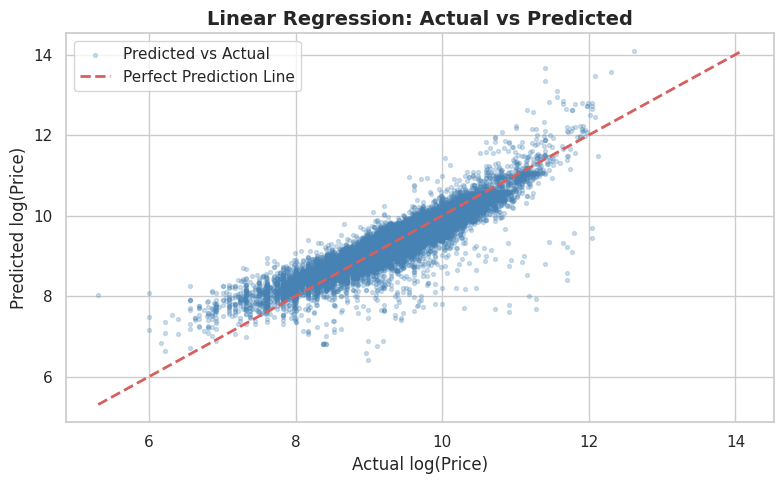

ℹ️  Points close to the red dashed line = accurate predictions
   Scatter away from the line = prediction errors


In [ ]:
# ── Actual vs Predicted Plot — Linear Regression ─────────────
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr, alpha=0.25, color='steelblue', s=8, label='Predicted vs Actual')
# Perfect prediction line: if predicted = actual, all points fall on this line
perfect_min = min(y_test.min(), y_pred_lr.min())
perfect_max = max(y_test.max(), y_pred_lr.max())
plt.plot([perfect_min, perfect_max], [perfect_min, perfect_max],
         'r--', linewidth=2, label='Perfect Prediction Line')

plt.xlabel('Actual log(Price)', fontsize=12)
plt.ylabel('Predicted log(Price)', fontsize=12)
plt.title('Linear Regression: Actual vs Predicted', fontweight='bold')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("ℹ️  Points close to the red dashed line = accurate predictions")
print("   Scatter away from the line = prediction errors")

---
## Step 6: Model 2 — Polynomial Regression

**The problem with Linear Regression:** It can only capture straight-line relationships. But in reality, a car's price might not drop *linearly* with age — it depreciates sharply in early years and then levels off.

**Polynomial Regression** solves this by adding **polynomial terms** to the features:
- Original: $x_1, x_2, \dots$
- After degree-2 polynomial: $x_1, x_2, x_1^2, x_2^2, x_1 x_2, \dots$

This lets the model fit **curved relationships** while still using the same Linear Regression algorithm under the hood.

> ⚙️ We use a **Pipeline** to chain the steps together cleanly:
> `PolynomialFeatures` → `StandardScaler` → `LinearRegression`

In [ ]:
# ── Polynomial Regression Pipeline (Degree = 2) ─────────────
# A Pipeline applies each step in sequence — very clean and prevents data leakage

poly_pipeline = Pipeline([
    ('poly',   PolynomialFeatures(degree=2, include_bias=False)),  # create x², x*y terms
    ('scaler', StandardScaler()),                                   # scale the new features
    ('model',  LinearRegression())                                  # fit the model
])

# Train on original unscaled data (the pipeline handles scaling internally)
poly_pipeline.fit(X_train, y_train)

# ── Make Predictions ─────────────────────────────────────────
y_pred_poly = poly_pipeline.predict(X_test)

# ── Compute Evaluation Metrics ───────────────────────────────
mae_poly  = mean_absolute_error(y_test, y_pred_poly)
mse_poly  = mean_squared_error(y_test, y_pred_poly)
rmse_poly = np.sqrt(mse_poly)
r2_poly   = r2_score(y_test, y_pred_poly)

# ── Display Results ──────────────────────────────────────────
print("=" * 48)
print("  POLYNOMIAL REGRESSION (deg=2) — RESULTS")
print("=" * 48)
print(f"  MAE   (Mean Absolute Error)      : {mae_poly:.4f}")
print(f"  RMSE  (Root Mean Squared Error)  : {rmse_poly:.4f}")
print(f"  R²    (Coefficient of Det.)      : {r2_poly:.4f}")
print("=" * 48)
print(f"\n  💡 Interpretation:")
print(f"     An R² of {r2_poly:.2%} means this model explains")
print(f"     {r2_poly:.2%} of the variance in log(car prices).")

  POLYNOMIAL REGRESSION (deg=2) — RESULTS
  MAE   (Mean Absolute Error)      : 0.2015
  RMSE  (Root Mean Squared Error)  : 0.2884
  R²    (Coefficient of Det.)      : 0.8504

  💡 Interpretation:
     An R² of 85.04% means this model explains
     85.04% of the variance in log(car prices).


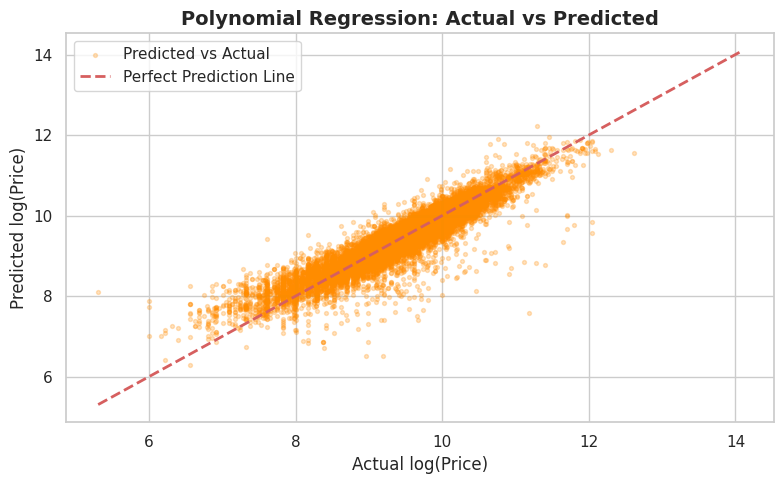

In [ ]:
# ── Actual vs Predicted Plot — Polynomial Regression ─────────
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_poly, alpha=0.25, color='darkorange', s=8, label='Predicted vs Actual')
plt.plot([perfect_min, perfect_max], [perfect_min, perfect_max],
         'r--', linewidth=2, label='Perfect Prediction Line')

plt.xlabel('Actual log(Price)', fontsize=12)
plt.ylabel('Predicted log(Price)', fontsize=12)
plt.title('Polynomial Regression: Actual vs Predicted', fontweight='bold')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

---
## Step 7: Model Comparison — Regression

Let's bring both models' results together for a direct comparison.

| Metric | Ideal Value | Notes |
|--------|-------------|-------|
| **MAE** | Lower is better | Average error in log-price units |
| **RMSE** | Lower is better | Penalizes large errors more |
| **R²** | Closer to 1.0 is better | Max possible = 1.0 |

In [ ]:
# ── Summary Comparison Table ─────────────────────────────────
comparison_reg = pd.DataFrame({
    'Model':  ['Linear Regression', 'Polynomial Regression (deg=2)'],
    'MAE':    [round(mae_lr, 4),   round(mae_poly, 4)],
    'RMSE':   [round(rmse_lr, 4),  round(rmse_poly, 4)],
    'R²':     [round(r2_lr, 4),    round(r2_poly, 4)]
})

print("=" * 58)
print("          REGRESSION MODEL COMPARISON")
print("=" * 58)
print(comparison_reg.to_string(index=False))
print("=" * 58)

# Highlight which model is better on each metric
better_mae  = 'Polynomial' if mae_poly  < mae_lr  else 'Linear'
better_rmse = 'Polynomial' if rmse_poly < rmse_lr else 'Linear'
better_r2   = 'Polynomial' if r2_poly   > r2_lr   else 'Linear'

print(f"\n  Best MAE  → {better_mae} Regression")
print(f"  Best RMSE → {better_rmse} Regression")
print(f"  Best R²   → {better_r2} Regression")

          REGRESSION MODEL COMPARISON
                        Model   MAE  RMSE    R²
            Linear Regression 0.221 0.317 0.819
Polynomial Regression (deg=2) 0.202 0.288 0.850

  Best MAE  → Polynomial Regression
  Best RMSE → Polynomial Regression
  Best R²   → Polynomial Regression


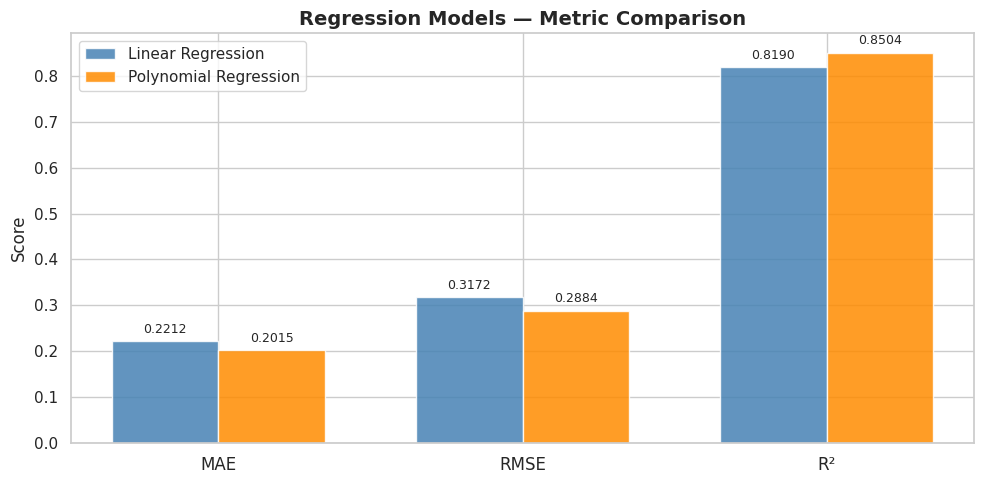

In [ ]:
# ── Bar Chart: Side-by-Side Metric Comparison ────────────────
metrics_reg  = ['MAE', 'RMSE', 'R²']
lr_vals   = [mae_lr,   rmse_lr,   r2_lr]
poly_vals = [mae_poly, rmse_poly, r2_poly]

x     = np.arange(len(metrics_reg))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars1 = ax.bar(x - width/2, lr_vals,   width, label='Linear Regression',       color='steelblue',  alpha=0.85)
bars2 = ax.bar(x + width/2, poly_vals, width, label='Polynomial Regression',    color='darkorange', alpha=0.85)

ax.set_title('Regression Models — Metric Comparison', fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(metrics_reg, fontsize=12)
ax.set_ylabel('Score')
ax.legend(fontsize=11)
ax.bar_label(bars1, fmt='%.4f', padding=4, fontsize=9)
ax.bar_label(bars2, fmt='%.4f', padding=4, fontsize=9)

plt.tight_layout()
plt.show()

---
## 💡 Part 1 — Results & Interpretation

### What did we learn?

**Linear Regression:**
- Our **baseline model** — simple, fast, and interpretable
- Assumes price has a straight-line relationship with each feature
- Works well when relationships are approximately linear

**Polynomial Regression (Degree = 2):**
- Adds squared terms and interaction terms between features
- Can capture **curved, non-linear patterns** (e.g., price drop is steep in early years, then flattens)
- If R² is noticeably higher → the non-linear relationships are important

### Which Model Won?
> Compare the **R²** values above:
> - A **higher R²** in Polynomial Regression suggests non-linearity in the data
> - If results are similar → the relationship is mostly linear, and the simpler Linear Regression may be preferred

### Important Note on Log-Price:
We predicted **log(price)** instead of raw price. To convert a prediction back to real price:
$$\text{price} = e^{\hat{y}} - 1$$

This transformation helps models learn better from price data that is highly skewed.

---
---

# 🛍️ PART 2: Customer Return Prediction
## Task: Binary Classification

**Goal:** Predict whether a customer will **return a purchased product** or not.

**Target Variable:** `return_status`
- `0` = Product was **NOT returned**
- `1` = Product **WAS returned**

**Dataset:** `Returns_data.csv` — customer transaction records

**Models to Apply:**
- **Logistic Regression** — a linear probabilistic classifier
- **Naïve Bayes** — a fast, probabilistic model based on Bayes' Theorem

---

## Step 1: Load the Returns Dataset

In [ ]:
# Load the customer returns dataset
df_ret = pd.read_csv('Returns_data.csv')

print(f"✅ Dataset loaded!")
print(f"   Rows   : {df_ret.shape[0]:,}")
print(f"   Columns: {df_ret.shape[1]}")
print(f"\nColumn names: {list(df_ret.columns)}")
print("\nFirst 5 rows:")
df_ret.head()

✅ Dataset loaded!
   Rows   : 2,300
   Columns: 11

Column names: ['product_price', 'customer_age', 'delivery_days', 'past_purchase_count', 'average_review_score', 'product_category', 'payment_method', 'shipping_type', 'customer_segment', 'discount_applied', 'return_status']

First 5 rows:


,product_price,customer_age,delivery_days,past_purchase_count,average_review_score,product_category,payment_method,shipping_type,customer_segment,discount_applied,return_status
0,95.790,37,2,9,4.400,Apparel,BNPL,Next-Day,Occasional,No,0
1,68.300,27,3,7,4.100,Jewelry,BNPL,Standard,New,Yes,0
2,140.600,37,4,2,3.600,Apparel,BNPL,Standard,Occasional,Yes,1
3,57.130,43,5,7,4.600,Jewelry,Credit Card,Express,Occasional,Yes,0
4,183.440,34,1,4,3.200,Jewelry,Credit Card,Express,Loyal,No,1


---
## Step 2: Exploratory Data Analysis (EDA)

Let's understand the returns dataset — its structure, missing values, and the distribution of our target variable.

In [ ]:
# ── 2.1 Dataset Info ────────────────────────────────────────
print("=" * 55)
print("  COLUMN INFORMATION")
print("=" * 55)
df_ret.info()

  COLUMN INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2300 entries, 0 to 2299
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   product_price         2300 non-null   float64
 1   customer_age          2300 non-null   int64  
 2   delivery_days         2300 non-null   int64  
 3   past_purchase_count   2300 non-null   int64  
 4   average_review_score  2300 non-null   float64
 5   product_category      2300 non-null   object 
 6   payment_method        2300 non-null   object 
 7   shipping_type         2300 non-null   object 
 8   customer_segment      2300 non-null   object 
 9   discount_applied      2300 non-null   object 
 10  return_status         2300 non-null   int64  
dtypes: float64(2), int64(4), object(5)
memory usage: 197.8+ KB


In [ ]:
# ── 2.2 Missing Values Check ────────────────────────────────
print("=" * 40)
print("  MISSING VALUES PER COLUMN")
print("=" * 40)
missing_ret = df_ret.isnull().sum()
if missing_ret.sum() == 0:
    print("  ✅ No missing values found!")
else:
    print(missing_ret[missing_ret > 0])

# ── 2.3 Summary Statistics ──────────────────────────────────
print("\nNumerical Summary:")
df_ret.describe()

  MISSING VALUES PER COLUMN
  ✅ No missing values found!

Numerical Summary:


,product_price,customer_age,delivery_days,past_purchase_count,average_review_score,return_status
count,2300.000,2300.000,2300.000,2300.000,2300.000,2300.000
mean,96.040,32.718,4.493,4.888,4.255,0.300
std,36.970,9.101,2.618,2.951,0.558,0.458
min,15.000,18.000,1.000,0.000,2.000,0.000
25%,70.595,26.000,3.000,3.000,4.000,0.000
50%,93.440,32.000,4.000,5.000,4.300,0.000
75%,119.245,39.000,6.000,7.000,4.700,1.000
max,274.110,64.000,14.000,15.000,5.000,1.000


  TARGET: return_status
  0 — Not Returned : 1,610  (70.0%)
  1 — Returned     : 690  (30.0%)


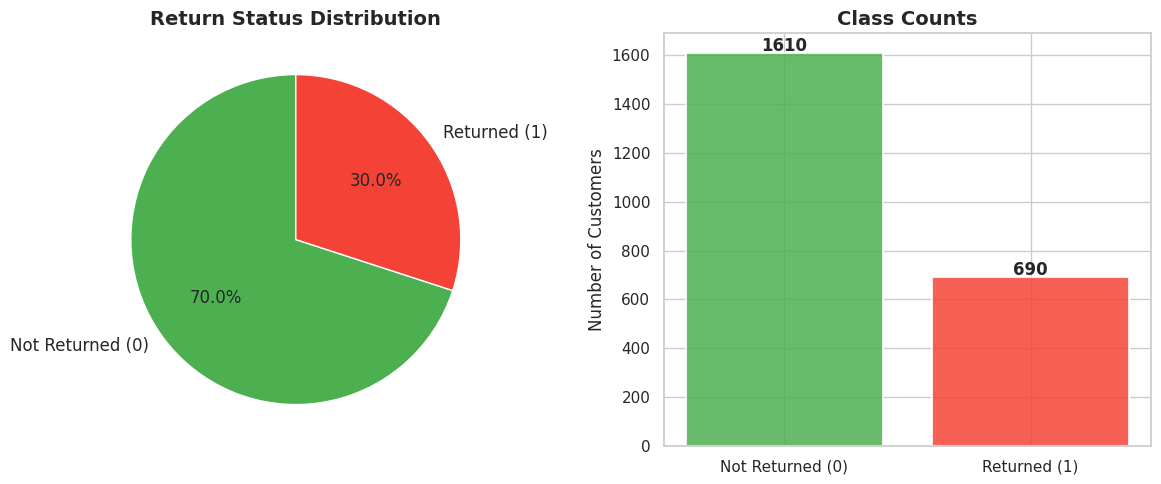

In [ ]:
# ── 2.4 Target Variable Distribution ─────────────────────────
counts = df_ret['return_status'].value_counts()
pcts   = df_ret['return_status'].value_counts(normalize=True) * 100

print("=" * 40)
print("  TARGET: return_status")
print("=" * 40)
print(f"  0 — Not Returned : {counts[0]:,}  ({pcts[0]:.1f}%)")
print(f"  1 — Returned     : {counts[1]:,}  ({pcts[1]:.1f}%)")
print("=" * 40)

# Visualize the class distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Pie chart
colors_pie = ['#4CAF50', '#F44336']
axes[0].pie([counts[0], counts[1]],
            labels=['Not Returned (0)', 'Returned (1)'],
            colors=colors_pie, autopct='%1.1f%%',
            startangle=90, textprops={'fontsize': 12})
axes[0].set_title('Return Status Distribution', fontweight='bold')

# Bar chart
axes[1].bar(['Not Returned (0)', 'Returned (1)'], [counts[0], counts[1]],
            color=colors_pie, alpha=0.85, edgecolor='white', linewidth=1.5)
axes[1].set_title('Class Counts', fontweight='bold')
axes[1].set_ylabel('Number of Customers')
for i, v in enumerate([counts[0], counts[1]]):
    axes[1].text(i, v + 10, str(v), ha='center', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

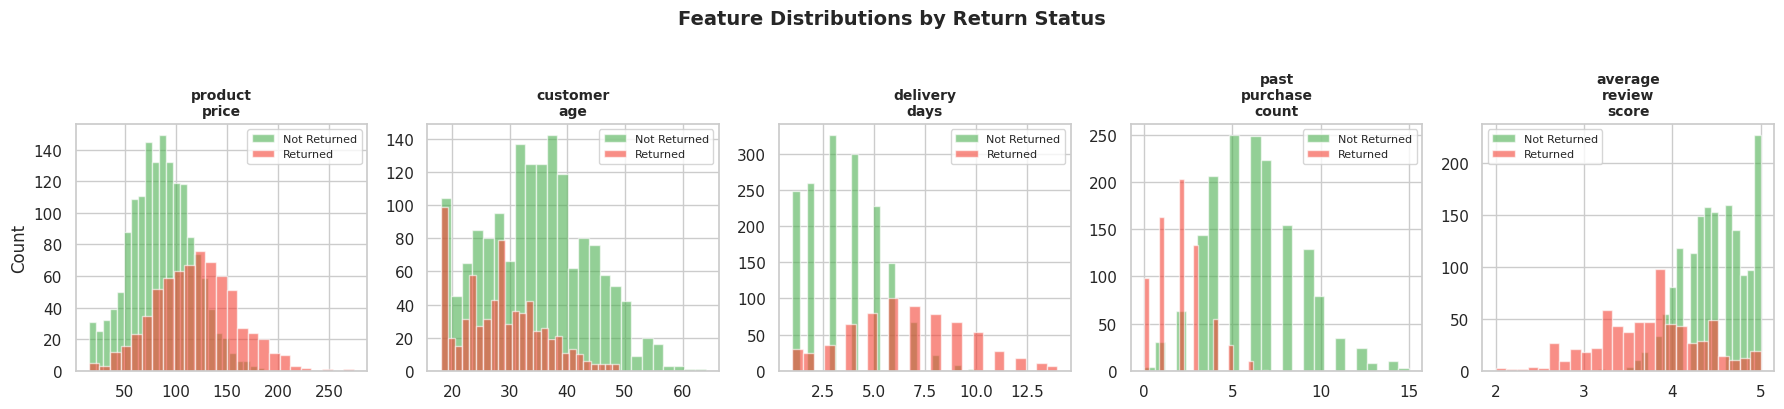

In [ ]:
# ── 2.5 Feature Distributions by Return Status ───────────────
num_features = ['product_price', 'customer_age', 'delivery_days',
                'past_purchase_count', 'average_review_score']

fig, axes = plt.subplots(1, len(num_features), figsize=(18, 4))

for i, col in enumerate(num_features):
    # Plot histogram for each class (returned vs not returned)
    for label, color in zip([0, 1], ['#4CAF50', '#F44336']):
        data = df_ret[df_ret['return_status'] == label][col]
        axes[i].hist(data, bins=25, alpha=0.6, color=color, edgecolor='white',
                     label=f'{"Returned" if label==1 else "Not Returned"}')
    axes[i].set_title(col.replace('_', '\n'), fontsize=10, fontweight='bold')
    axes[i].set_ylabel('Count' if i == 0 else '')
    axes[i].legend(fontsize=8)

plt.suptitle('Feature Distributions by Return Status', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

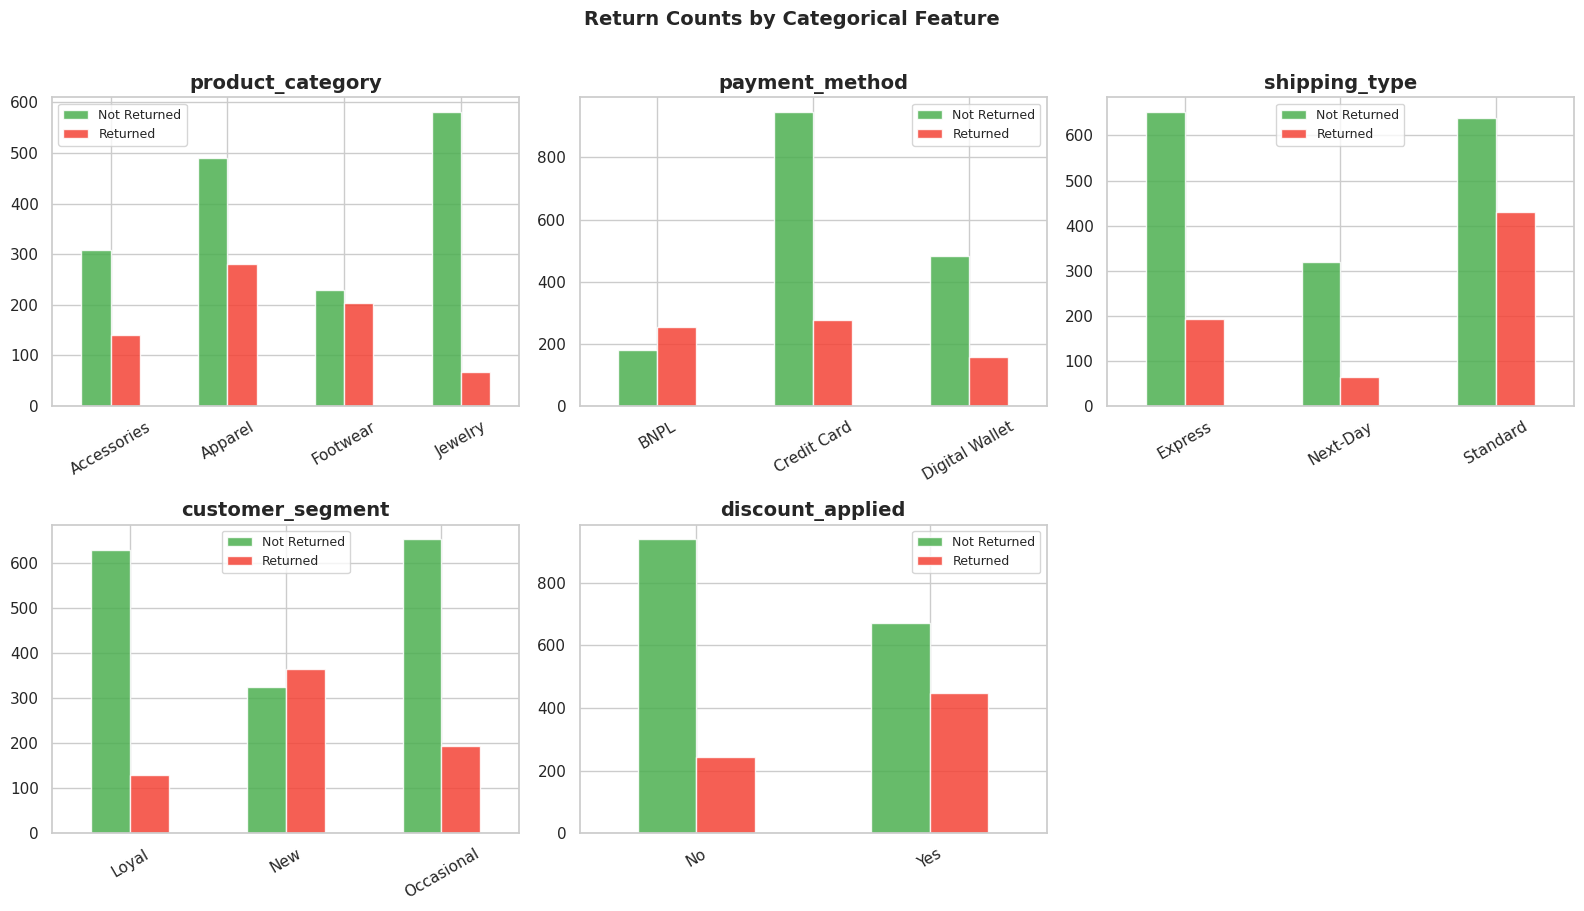

In [ ]:
# ── 2.6 Categorical Feature Counts by Return Status ──────────
cat_features = ['product_category', 'payment_method', 'shipping_type',
                'customer_segment', 'discount_applied']

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(cat_features):
    cross = df_ret.groupby([col, 'return_status']).size().unstack(fill_value=0)
    cross.plot(kind='bar', ax=axes[i], color=['#4CAF50', '#F44336'],
               alpha=0.85, edgecolor='white')
    axes[i].set_title(f'{col}', fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(['Not Returned', 'Returned'], fontsize=9)

axes[-1].axis('off')   # hide the last empty subplot
plt.suptitle('Return Counts by Categorical Feature', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Step 3: Data Preprocessing, Train-Test Split & Encoding

The correct order to prevent data leakage:

```
1. Drop nulls  →  2. Separate X and y  →  3. Train-Test Split  →  4. Encode X_train (fit) + X_test (transform)  →  5. Scale
```

**Why One-Hot Encoding instead of Label Encoding?**
Label Encoding assigns integers (e.g., `BNPL=0`, `Credit Card=1`, `Debit Card=2`), which implies a false ordering. One-Hot Encoding creates separate binary columns for each category, avoiding this problem.

> ⚠️ **Leakage rule:** `pd.get_dummies()` must be applied **after splitting** — fitting on the full dataset lets the test set's unique categories influence column structure. We apply it to train and test separately, then align the columns.

In [ ]:
# ── 3.1 Drop Missing Values ─────────────────────────────────
df_class = df_ret.copy()
before = len(df_class)
df_class = df_class.dropna()
dropped = before - len(df_class)
print(f"{'Dropped ' + str(dropped) + ' rows with null values.' if dropped > 0 else '✅ No missing values — no rows dropped.'}")

# ── 3.2 Separate Features (X) and Target (y) ────────────────
X_cls = df_class.drop(columns=['return_status'])
y_cls = df_class['return_status']

# ── 3.3 Train-Test Split — BEFORE any encoding ───────────────
# The encoder must never see the test set during fitting
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_cls, y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls   # preserves class balance in both splits
)

print(f"\n✅ Data split (stratified, done before encoding):")
print(f"   Training: {len(X_train_c):,} samples | Returns: {y_train_c.sum()}")
print(f"   Testing : {len(X_test_c):,} samples  | Returns: {y_test_c.sum()}")

# ── 3.4 One-Hot Encode AFTER Splitting ───────────────────────
# Apply get_dummies to train and test SEPARATELY
cat_cols_to_encode = [
    'product_category', 'payment_method',
    'shipping_type', 'customer_segment', 'discount_applied'
]

X_train_c = pd.get_dummies(X_train_c, columns=cat_cols_to_encode, drop_first=True)
X_test_c  = pd.get_dummies(X_test_c,  columns=cat_cols_to_encode, drop_first=True)

# Align columns: test set must have the exact same columns as training set
# reindex fills any missing dummy columns with 0, and drops any test-only extras
X_test_c = X_test_c.reindex(columns=X_train_c.columns, fill_value=0)

print(f"\n✅ One-Hot Encoding applied separately to train and test sets")
print(f"   Training shape: {X_train_c.shape}")
print(f"   Test shape    : {X_test_c.shape}  (columns aligned to training)")

# ── 3.5 Feature Scaling — fit on training ONLY ───────────────
scaler_cls = StandardScaler()
X_train_c_scaled = scaler_cls.fit_transform(X_train_c)
X_test_c_scaled  = scaler_cls.transform(X_test_c)

print(f"\n✅ Features scaled using StandardScaler (fit on training only)")
print(f"\nAll features ({X_train_c.shape[1]} total):")
for col in X_train_c.columns:
    print(f"  • {col}")

✅ No missing values — no rows dropped.

✅ Data split (stratified, done before encoding):
   Training: 1,840 samples | Returns: 552
   Testing : 460 samples  | Returns: 138

✅ One-Hot Encoding applied separately to train and test sets
   Training shape: (1840, 15)
   Test shape    : (460, 15)  (columns aligned to training)

✅ Features scaled using StandardScaler (fit on training only)

All features (15 total):
  • product_price
  • customer_age
  • delivery_days
  • past_purchase_count
  • average_review_score
  • product_category_Apparel
  • product_category_Footwear
  • product_category_Jewelry
  • payment_method_Credit Card
  • payment_method_Digital Wallet
  • shipping_type_Next-Day
  • shipping_type_Standard
  • customer_segment_New
  • customer_segment_Occasional
  • discount_applied_Yes


---
## Step 4: Model 1 — Logistic Regression

Despite its name, **Logistic Regression** is a **classification** algorithm.

It models the **probability** that a customer returns a product:

$$P(\text{return}=1) = \frac{1}{1 + e^{-(w_0 + w_1 x_1 + \dots + w_n x_n)}}$$

The **sigmoid function** squashes the output to a value between 0 and 1.
If the probability is **> 0.5**, the model predicts "Returned" (class 1).

**Evaluation Metrics for Classification:**
| Metric | Meaning |
|--------|---------|
| **Accuracy** | % of all predictions that are correct |
| **Precision** | Of those predicted as "Returned", how many actually were? |
| **Recall** | Of all actual returns, how many did we catch? |
| **F1-Score** | Harmonic mean of Precision and Recall |
| **ROC-AUC** | Model's ability to distinguish between classes (0.5 = random, 1.0 = perfect) |

In [ ]:
# ── Train Logistic Regression ────────────────────────────────
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_c_scaled, y_train_c)

# ── Make Predictions ─────────────────────────────────────────
y_pred_lr_c = log_reg.predict(X_test_c_scaled)
y_prob_lr_c = log_reg.predict_proba(X_test_c_scaled)[:, 1]  # probability of class 1

# ── Compute Metrics ──────────────────────────────────────────
acc_lr  = accuracy_score(y_test_c, y_pred_lr_c)
prec_lr = precision_score(y_test_c, y_pred_lr_c)
rec_lr  = recall_score(y_test_c, y_pred_lr_c)
f1_lr   = f1_score(y_test_c, y_pred_lr_c)
auc_lr  = roc_auc_score(y_test_c, y_prob_lr_c)

# ── Display Results ──────────────────────────────────────────
print("=" * 50)
print("     LOGISTIC REGRESSION — RESULTS")
print("=" * 50)
print(f"  Accuracy  : {acc_lr:.4f}   ({acc_lr:.1%})")
print(f"  Precision : {prec_lr:.4f}")
print(f"  Recall    : {rec_lr:.4f}")
print(f"  F1-Score  : {f1_lr:.4f}")
print(f"  ROC-AUC   : {auc_lr:.4f}")
print("=" * 50)

print("\nDetailed Classification Report:")
print(classification_report(y_test_c, y_pred_lr_c,
                             target_names=['Not Returned (0)', 'Returned (1)']))

     LOGISTIC REGRESSION — RESULTS
  Accuracy  : 0.9565   (95.7%)
  Precision : 0.9538
  Recall    : 0.8986
  F1-Score  : 0.9254
  ROC-AUC   : 0.9947

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Returned (0)       0.96      0.98      0.97       322
    Returned (1)       0.95      0.90      0.93       138

        accuracy                           0.96       460
       macro avg       0.96      0.94      0.95       460
    weighted avg       0.96      0.96      0.96       460



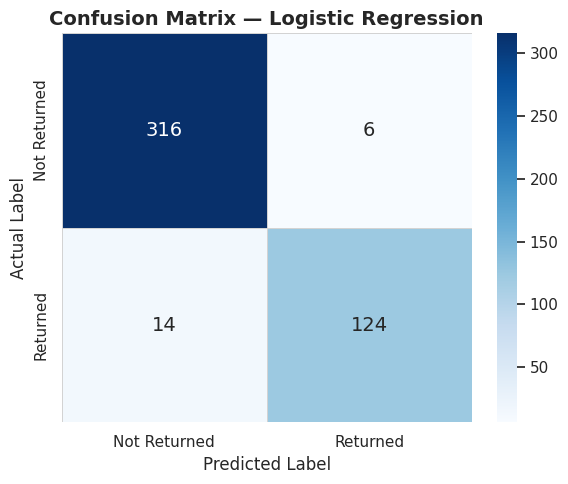

  Confusion Matrix Interpretation:
  +------------------+------------------+
  | True Negative    | False Positive   |
  | Correctly said   | Predicted return,|
  | Not Returned     | but was NOT      |
  +------------------+------------------+
  | False Negative   | True Positive    |
  | Predicted no     | Correctly said   |
  | return, but DID  | Returned         |
  +------------------+------------------+



In [ ]:
# ── Confusion Matrix: Logistic Regression ────────────────────
cm_lr = confusion_matrix(y_test_c, y_pred_lr_c)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Not Returned', 'Returned'],
    yticklabels=['Not Returned', 'Returned'],
    linewidths=0.5, linecolor='lightgray',
    annot_kws={'size': 14}
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix — Logistic Regression', fontweight='bold')
plt.tight_layout()
plt.show()

print(
    "  Confusion Matrix Interpretation:\n"
    "  +------------------+------------------+\n"
    "  | True Negative    | False Positive   |\n"
    "  | Correctly said   | Predicted return,|\n"
    "  | Not Returned     | but was NOT      |\n"
    "  +------------------+------------------+\n"
    "  | False Negative   | True Positive    |\n"
    "  | Predicted no     | Correctly said   |\n"
    "  | return, but DID  | Returned         |\n"
    "  +------------------+------------------+\n"
)

---
## Step 5: Model 2 — Naïve Bayes

**Naïve Bayes** is a probabilistic classifier based on **Bayes' Theorem**:

$$P(\text{Return} \mid \text{features}) \propto P(\text{features} \mid \text{Return}) \times P(\text{Return})$$

It is called **"naïve"** because it assumes all features are **independent** of each other — which is rarely true in real life, but the model still performs surprisingly well in practice!

**Types of Naïve Bayes:**
| Type | When to use |
|------|------------|
| **Gaussian NB** | When features are continuous numbers (our case) |
| Multinomial NB | When features are word counts (text classification) |
| Bernoulli NB | When features are binary (0/1) |

We use **Gaussian Naïve Bayes** since our numerical features are continuous.

In [ ]:
# ── Train Naïve Bayes ────────────────────────────────────────
nb_model = GaussianNB()
nb_model.fit(X_train_c_scaled, y_train_c)

# ── Make Predictions ─────────────────────────────────────────
y_pred_nb = nb_model.predict(X_test_c_scaled)
y_prob_nb = nb_model.predict_proba(X_test_c_scaled)[:, 1]   # probability of class 1

# ── Compute Metrics ──────────────────────────────────────────
acc_nb  = accuracy_score(y_test_c, y_pred_nb)
prec_nb = precision_score(y_test_c, y_pred_nb)
rec_nb  = recall_score(y_test_c, y_pred_nb)
f1_nb   = f1_score(y_test_c, y_pred_nb)
auc_nb  = roc_auc_score(y_test_c, y_prob_nb)

# ── Display Results ──────────────────────────────────────────
print("=" * 50)
print("       NAÏVE BAYES — RESULTS")
print("=" * 50)
print(f"  Accuracy  : {acc_nb:.4f}   ({acc_nb:.1%})")
print(f"  Precision : {prec_nb:.4f}")
print(f"  Recall    : {rec_nb:.4f}")
print(f"  F1-Score  : {f1_nb:.4f}")
print(f"  ROC-AUC   : {auc_nb:.4f}")
print("=" * 50)

print("\nDetailed Classification Report:")
print(classification_report(y_test_c, y_pred_nb,
                             target_names=['Not Returned (0)', 'Returned (1)']))

       NAÏVE BAYES — RESULTS
  Accuracy  : 0.9478   (94.8%)
  Precision : 0.9191
  Recall    : 0.9058
  F1-Score  : 0.9124
  ROC-AUC   : 0.9918

Detailed Classification Report:
                  precision    recall  f1-score   support

Not Returned (0)       0.96      0.97      0.96       322
    Returned (1)       0.92      0.91      0.91       138

        accuracy                           0.95       460
       macro avg       0.94      0.94      0.94       460
    weighted avg       0.95      0.95      0.95       460



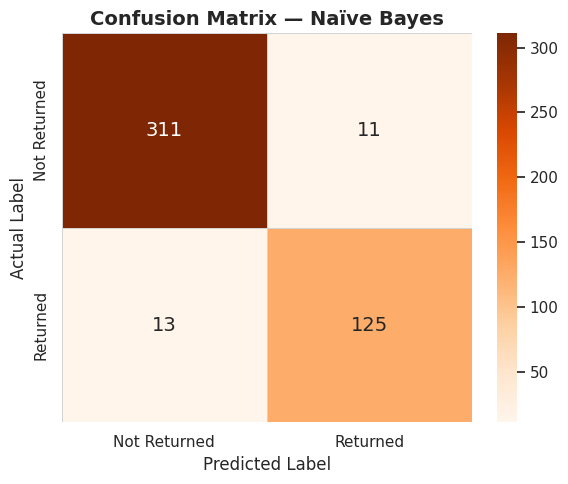

In [ ]:
# ── Confusion Matrix: Naïve Bayes ────────────────────────────
cm_nb = confusion_matrix(y_test_c, y_pred_nb)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_nb, annot=True, fmt='d', cmap='Oranges',
    xticklabels=['Not Returned', 'Returned'],
    yticklabels=['Not Returned', 'Returned'],
    linewidths=0.5, linecolor='lightgray',
    annot_kws={'size': 14}
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('Actual Label', fontsize=12)
plt.title('Confusion Matrix — Naïve Bayes', fontweight='bold')
plt.tight_layout()
plt.show()

---
## Step 6: ROC-AUC Curves

The **ROC Curve** (Receiver Operating Characteristic) is a powerful visualization for binary classifiers.

- **X-axis:** False Positive Rate = how often we incorrectly flag a non-return as a return
- **Y-axis:** True Positive Rate (Recall) = how often we correctly catch actual returns

The **AUC (Area Under the ROC Curve):**
- `AUC = 1.0` → **Perfect** classifier
- `AUC = 0.5` → **Random guessing** (dashed diagonal line)
- Our models should score between 0.5 and 1.0

> **The higher the AUC, the better the model is at distinguishing returned from non-returned items.**

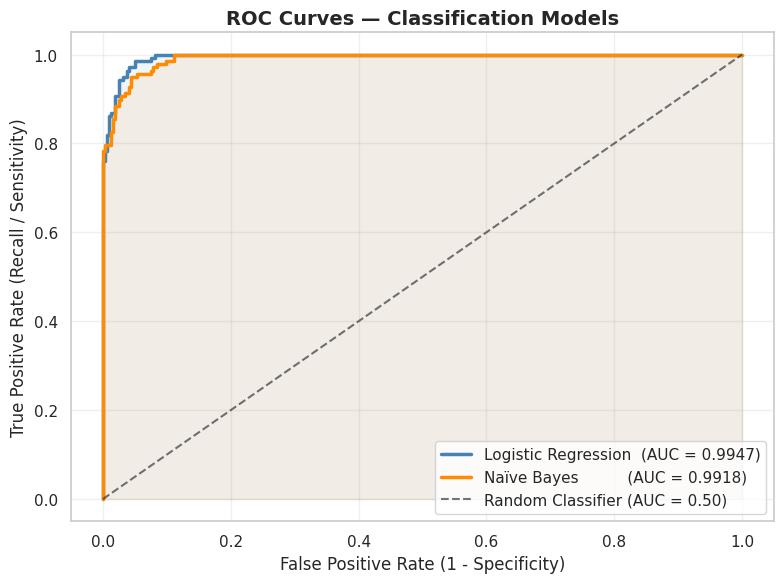

In [ ]:
# ── Calculate ROC Curves ─────────────────────────────────────
fpr_lr, tpr_lr, _ = roc_curve(y_test_c, y_prob_lr_c)
fpr_nb, tpr_nb, _ = roc_curve(y_test_c, y_prob_nb)

# ── Plot ROC Curves ──────────────────────────────────────────
plt.figure(figsize=(8, 6))

plt.plot(fpr_lr, tpr_lr, color='steelblue',  lw=2.5,
         label=f'Logistic Regression  (AUC = {auc_lr:.4f})')
plt.plot(fpr_nb, tpr_nb, color='darkorange', lw=2.5,
         label=f'Naïve Bayes          (AUC = {auc_nb:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6,
         label='Random Classifier (AUC = 0.50)')

# Shade the area under the LR curve
plt.fill_between(fpr_lr, tpr_lr, alpha=0.08, color='steelblue')
plt.fill_between(fpr_nb, tpr_nb, alpha=0.08, color='darkorange')

plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=12)
plt.title('ROC Curves — Classification Models', fontweight='bold', fontsize=14)
plt.legend(fontsize=11, loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
## Step 7: Model Comparison — Classification

Let's compile all metrics for a clear, side-by-side comparison.

In [ ]:
# ── Final Summary Table ──────────────────────────────────────
comparison_cls = pd.DataFrame({
    'Model':     ['Logistic Regression', 'Naïve Bayes'],
    'Accuracy':  [round(acc_lr, 4),  round(acc_nb, 4)],
    'Precision': [round(prec_lr, 4), round(prec_nb, 4)],
    'Recall':    [round(rec_lr, 4),  round(rec_nb, 4)],
    'F1-Score':  [round(f1_lr, 4),   round(f1_nb, 4)],
    'ROC-AUC':   [round(auc_lr, 4),  round(auc_nb, 4)]
})

print("=" * 68)
print("          CLASSIFICATION MODEL COMPARISON")
print("=" * 68)
print(comparison_cls.to_string(index=False))
print("=" * 68)

          CLASSIFICATION MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression     0.957      0.954   0.899     0.925    0.995
        Naïve Bayes     0.948      0.919   0.906     0.912    0.992


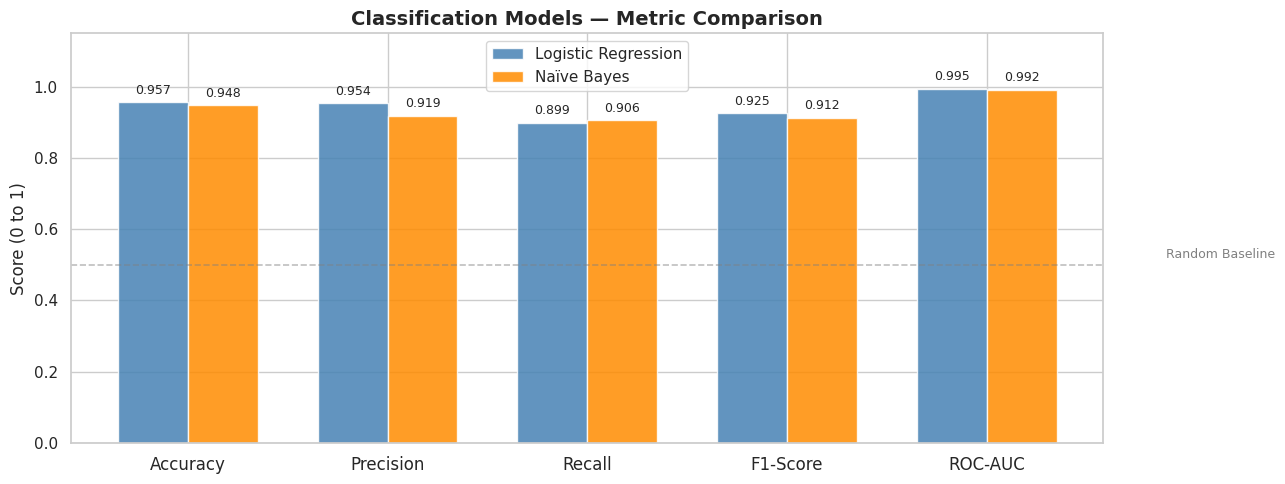

In [ ]:
# ── Bar Chart: Metric Comparison ─────────────────────────────
metrics_cls  = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC']
lr_cls_vals  = [acc_lr,  prec_lr, rec_lr,  f1_lr,  auc_lr]
nb_cls_vals  = [acc_nb,  prec_nb, rec_nb,  f1_nb,  auc_nb]

x     = np.arange(len(metrics_cls))
width = 0.35

fig, ax = plt.subplots(figsize=(13, 5))

bars1 = ax.bar(x - width/2, lr_cls_vals, width,
               label='Logistic Regression', color='steelblue', alpha=0.85)
bars2 = ax.bar(x + width/2, nb_cls_vals, width,
               label='Naïve Bayes',         color='darkorange', alpha=0.85)

ax.set_title('Classification Models — Metric Comparison', fontweight='bold')
ax.set_ylim(0, 1.15)
ax.axhline(0.5, color='gray', linestyle='--', alpha=0.5, linewidth=1.2)
ax.text(len(metrics_cls)-0.1, 0.52, 'Random Baseline', color='gray', fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(metrics_cls, fontsize=12)
ax.set_ylabel('Score (0 to 1)')
ax.legend(fontsize=11)
ax.bar_label(bars1, fmt='%.3f', padding=4, fontsize=9)
ax.bar_label(bars2, fmt='%.3f', padding=4, fontsize=9)

plt.tight_layout()
plt.show()

---
## 💡 Part 2 — Results & Interpretation

### What the Metrics Tell Us

| Metric | What it means in this context |
|--------|------------------------------|
| **Accuracy** | Of all customers, what % did we correctly classify? |
| **Precision** | Of customers we predicted would return, how many actually did? (False alarms) |
| **Recall** | Of all actual returns, how many did we successfully predict? (Missed returns) |
| **F1-Score** | Best single metric when the two classes are not perfectly balanced |
| **ROC-AUC** | Overall ability to rank returning customers above non-returning ones |

### Which Model is Better?

**Logistic Regression:**
> A linear model that finds the best hyperplane to separate returning vs. non-returning customers. Generally robust and produces well-calibrated probabilities.

**Naïve Bayes:**
> Makes the simplifying assumption that features are independent. This is rarely true (e.g., `product_price` and `discount_applied` are likely correlated), but the model can still work well.

**Decision Rule:**
- If **Logistic Regression** achieves higher F1-Score and AUC → prefer it (more reliable with correlated features)
- If **Naïve Bayes** has higher Recall → it catches more actual returns (valuable for e-commerce)

> 🏪 **Business Context:** In e-commerce, missing a true return (False Negative) may be more costly than a false alarm (False Positive). This makes **Recall** especially important when choosing between models.

---
---

# 📋 Final Assignment Summary

This cell prints a complete summary of all model results once all cells above have been run.

In [ ]:
# ============================================================
#  FINAL ASSIGNMENT SUMMARY — prints all results in one place
# ============================================================

line = "=" * 68

# ── PART 1: REGRESSION ───────────────────────────────────────
print(line)
print("  PART 1: USED CAR PRICE PREDICTION — REGRESSION RESULTS")
print(line)
print(f"  {'Model':<35} {'MAE':>8} {'RMSE':>8} {'R²':>8}")
print(f"  {'-'*35} {'-'*8} {'-'*8} {'-'*8}")
print(f"  {'Linear Regression':<35} {mae_lr:>8.4f} {rmse_lr:>8.4f} {r2_lr:>8.4f}")
print(f"  {'Polynomial Regression (deg=2)':<35} {mae_poly:>8.4f} {rmse_poly:>8.4f} {r2_poly:>8.4f}")
print(line)

reg_winner = "Polynomial Regression" if r2_poly > r2_lr else "Linear Regression"
print(f"\n  ✅ Better R²: {reg_winner}")
print(f"  Note: metrics are in log(price) units — lower MAE/RMSE and higher R² is better.")
print(f"  To convert a prediction back to SAR: price = exp(log_price) - 1  [np.expm1()]")

print()

# ── PART 2: CLASSIFICATION ───────────────────────────────────
print(line)
print("  PART 2: CUSTOMER RETURN PREDICTION — CLASSIFICATION RESULTS")
print(line)
print(f"  {'Model':<25} {'Accuracy':>9} {'Precision':>10} {'Recall':>8} {'F1':>8} {'AUC':>8}")
print(f"  {'-'*25} {'-'*9} {'-'*10} {'-'*8} {'-'*8} {'-'*8}")
print(f"  {'Logistic Regression':<25} {acc_lr:>9.4f} {prec_lr:>10.4f} {rec_lr:>8.4f} {f1_lr:>8.4f} {auc_lr:>8.4f}")
print(f"  {'Naïve Bayes':<25} {acc_nb:>9.4f} {prec_nb:>10.4f} {rec_nb:>8.4f} {f1_nb:>8.4f} {auc_nb:>8.4f}")
print(line)

cls_winner = "Logistic Regression" if f1_lr >= f1_nb else "Naïve Bayes"
print(f"\n  ✅ Higher F1-Score: {cls_winner}")
print(f"  Note: In e-commerce, Recall is especially important (catching actual returns).")

print()
print(line)
print("  KEY TAKEAWAYS")
print(line)
print("  1. Polynomial Regression captures non-linear patterns Linear Regression misses.")
print("  2. Log-transforming the price (log1p) helps models work better on skewed data.")
print("  3. Accuracy alone can mislead on imbalanced classes — use F1 and ROC-AUC.")
print("  4. Both classifiers were trained with stratified splits to preserve class balance.")
print("  5. All encoders and scalers were fit on training data ONLY to prevent leakage.")
print(line)

  PART 1: USED CAR PRICE PREDICTION — REGRESSION RESULTS
  Model                                    MAE     RMSE       R²
  ----------------------------------- -------- -------- --------
  Linear Regression                     0.2212   0.3172   0.8190
  Polynomial Regression (deg=2)         0.2015   0.2884   0.8504

  ✅ Better R²: Polynomial Regression
  Note: metrics are in log(price) units — lower MAE/RMSE and higher R² is better.
  To convert a prediction back to SAR: price = exp(log_price) - 1  [np.expm1()]

  PART 2: CUSTOMER RETURN PREDICTION — CLASSIFICATION RESULTS
  Model                      Accuracy  Precision   Recall       F1      AUC
  ------------------------- --------- ---------- -------- -------- --------
  Logistic Regression          0.9565     0.9538   0.8986   0.9254   0.9947
  Naïve Bayes                  0.9478     0.9191   0.9058   0.9124   0.9918

  ✅ Higher F1-Score: Logistic Regression
  Note: In e-commerce, Recall is especially important (catching actual ret